In [2]:
import pandas as pd
import numpy as np

In [3]:
data_dir = r"ai4omics-data-challenge-cancers-main"
X_normal = pd.read_csv(f"{data_dir}/T2_X_normal.csv", sep=';', index_col=0)
y_normal = pd.read_csv(f"{data_dir}/T2_y_normal.csv", sep=';', index_col=0)

print("Normal X shape:", X_normal.shape)
print("Normal y shape:", y_normal.shape)
print("\nNormal Tissues count:")
print(y_normal['tissue'].value_counts())

Normal X shape: (580, 5135)
Normal y shape: (580, 2)

Normal Tissues count:
tissue
Brain     323
Breast    176
Liver      81
Name: count, dtype: int64


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
# 1. Standardize normal tissue gene expression data
scaler = StandardScaler()
X_normal_scaled = scaler.fit_transform(X_normal)
# 2. Apply PCA to project 5,135 genes into 2 principal components
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_normal_scaled)
# Calculate and print explained variance ratio
print("PC1 Information:", f"{pca.explained_variance_ratio_[0]*100:.2f}%")
print("PC2 Information:", f"{pca.explained_variance_ratio_[1]*100:.2f}%")
print("Total Information:", f"{sum(pca.explained_variance_ratio_)*100:.2f}%")

PC1 Information: 29.83%
PC2 Information: 22.26%
Total Information: 52.09%


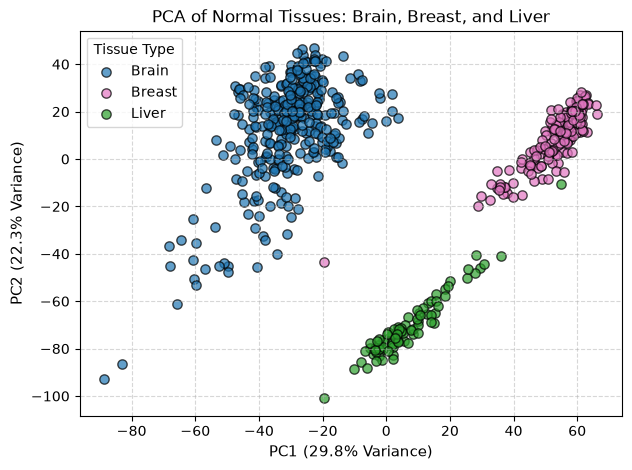

In [7]:
plt.figure(figsize=(7, 5))

# Define color palette for distinct normal tissues
colors = {'Brain': '#1f77b4', 'Breast': '#e377c2', 'Liver': '#2ca02c'}

# Scatter plot points for each tissue type
for tissue, color in colors.items():
    mask = (y_normal['tissue'] == tissue).values
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], c=color, label=tissue, alpha=0.7, edgecolors='k', s=45)

# Set axes labels, legend, and aesthetics
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)", fontsize=11)
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)", fontsize=11)
plt.title("PCA of Normal Tissues: Brain, Breast, and Liver", fontsize=12)
plt.legend(title="Tissue Type")
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 1. Initialize Random Forest classifier (300 estimators)
rf_model = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)

# 2. Evaluate model performance via 5-Fold Stratified Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(rf_model, X_normal, y_normal['tissue'], cv=cv, scoring='accuracy')

print("5 Folds Accuracy:", scores)
print(f"Mean Accuracy: {scores.mean() * 100:.2f}%")

5 Folds ki Accuracy: [1.         1.         1.         0.98275862 1.        ]
Mean Accuracy: 99.66%


In [9]:
# 1. Load unlabeled cancer gene expression data
X_cancer = pd.read_csv(f"{data_dir}/T2_X_cancer.csv", sep=';', index_col=0)
y_cancer = pd.read_csv(f"{data_dir}/T2_y_cancer.csv", sep=';', index_col=0)

# 2. Fit Random Forest model on complete normal tissue dataset
rf_model.fit(X_normal, y_normal['tissue'])

# 3. Predict primary tissue origin for 1,628 cancer samples
cancer_preds = rf_model.predict(X_cancer)

# 4. Inspect predicted cancer tissue counts
pred_counts = pd.Series(cancer_preds).value_counts()
print("Predicted Cancer Tissues:")
print(pred_counts)

Predicted Cancer Tissues:
Breast    773
Brain     507
Liver     348
Name: count, dtype: int64


In [10]:
# Assign predicted tissue labels to cancer annotations
y_cancer['tissue'] = cancer_preds

# Check predicted tissue distribution
print(y_cancer.head())
print("\nTissue distribution in cancer samples:")
print(y_cancer['tissue'].value_counts())

          status  tissue  subtype
id_sample                        
SM0649     tumor  Breast      NaN
SM0811     tumor  Breast      NaN
SM1547     tumor   Brain      NaN
SM0400     tumor  Breast      NaN
SM0639     tumor  Breast      NaN

Tissue distribution in cancer samples:
tissue
Breast    773
Brain     507
Liver     348
Name: count, dtype: int64


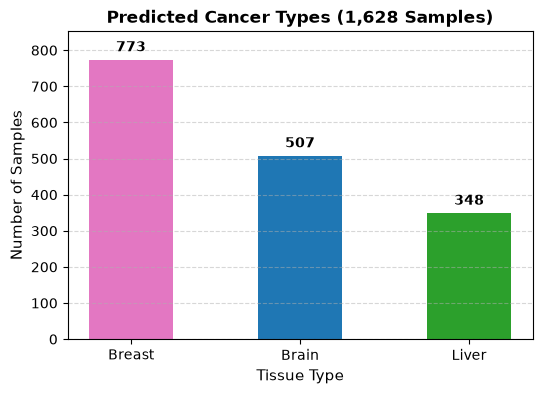

In [11]:
# Compute distribution counts of predicted cancer types
tissue_counts = y_cancer['tissue'].value_counts()

# Plot distribution bar chart for final presentation
plt.figure(figsize=(6, 4))
bars = plt.bar(tissue_counts.index, tissue_counts.values, color=['#e377c2', '#1f77b4', '#2ca02c'], width=0.5)

# Annotate bar heights with count values
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 15, f"{int(yval)}", ha='center', va='bottom', fontweight='bold')

plt.title("Predicted Cancer Types (1,628 Samples)", fontsize=12, fontweight='bold')
plt.xlabel("Tissue Type", fontsize=11)
plt.ylabel("Number of Samples", fontsize=11)
plt.ylim(0, max(tissue_counts.values) + 80)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

Task 2

In [14]:
# 1. Load PAM50 breast cancer signature gene panel
pam50_df = pd.read_csv(f"{data_dir}/gene_list_pam50_breast_cancer.csv", sep=';')

# 2. Intersect PAM50 genes with dataset features
common_genes = [g for g in pam50_df['gene_symbol'] 
 if g in X_cancer.columns]
print(f"Dataset mein PAM50 genes mojood hain: {len(common_genes)} / 50")

# 3. Filter cancer samples identified as Breast tumors
breast_mask = (y_cancer['tissue'] == 'Breast') & (y_cancer['status'] == 'tumor')
X_breast = X_cancer.loc[breast_mask, common_genes]

print(f"Total Breast Cancer Samples: {X_breast.shape[0]}")
print(f"Features (PAM50 genes): {X_breast.shape[1]}")

Dataset mein PAM50 genes mojood hain: 48 / 50
Total Breast Cancer Samples: 773
Features (PAM50 genes): 48


In [13]:
from sklearn.cluster import KMeans

# 1. Standardize PAM50 gene expression subset
scaler_pam = StandardScaler()
X_breast_scaled = scaler_pam.fit_transform(X_breast)

# 2. Cluster breast cancer samples using K-Means (k=2)
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_breast_scaled)

# 3. Identify cluster centroids with high ESR1 and PGR expression
df_check = pd.DataFrame({
    'cluster': clusters,
    'ESR1': X_breast['ESR1'],
    'PGR': X_breast['PGR']
})

print("Cluster wise average expression:")
print(df_check.groupby('cluster').mean())

Cluster wise average expression:
             ESR1       PGR
cluster                    
0        0.178232  0.004525
1        3.988551  1.890802


In [16]:
# 1. Ensure subtype column has object dtype to prevent type conversion issues
y_cancer['subtype'] = y_cancer['subtype'].astype(object)

# 2. Assign Luminal-A to the cluster with high ESR1 expression (Basal-like otherwise)
luminal_cluster = df_check.groupby('cluster')['ESR1'].mean().idxmax()
subtypes = np.where(clusters == luminal_cluster, 'Luminal-A', 'Basal-like')

# 3. Populate subtype annotations for breast cancer samples only
y_cancer.loc[breast_mask, 'subtype'] = subtypes

# 4. Verify molecular subtype distribution
print("Breast Cancer Subtypes Distribution:")
print(y_cancer['subtype'].value_counts())

# 5. Save completed submission file with semicolon delimiter
y_cancer.to_csv("T2_y_cancer.csv", sep=';')
print("\nFinal T2_y_cancer.csv successfully saved!")

Breast Cancer Subtypes Distribution:
subtype
Luminal-A     573
Basal-like    200
Name: count, dtype: int64

Final T2_y_cancer.csv successfully saved!
